# 1. Carregamento e Inspeção Inicial do Dataset
Nesta etapa, importamos as bibliotecas essenciais (`pandas`, `numpy`, `matplotlib` e `seaborn`), carregamos os dados do arquivo CSV e fazemos a conversão dos campos de data para o formato datetime.

Além disso, exibimos tanto as **primeiras** quanto as **últimas** linhas para validar se o arquivo foi carregado integralmente.

In [5]:
# 0. Instalação das dependências (rode apenas uma vez)
!pip install pandas numpy matplotlib seaborn scikit-learn -q

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Carregamento do dataset
caminho_arquivo = "../data/raw/food_delivery_orders_dataset.csv"
df = pd.read_csv(caminho_arquivo)

# Conversão de datas
df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])
df["order_date"] = pd.to_datetime(df["order_date"])


In [12]:
print("--- Primeiras 5 linhas ---")
display(df.head())

print("--- Últimas 5 linhas ---")
display(df.tail())

print(
    f"\nDimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.\n"
)
df.info()

--- Primeiras 5 linhas ---


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


--- Últimas 5 linhas ---


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
49995,ORD_049996,CUS_00280,RES_0130,DRV_0112,2025-10-25 12:16:00,2025-10-25,12,Saturday,1,City_B,...,Medium,34,5.0,11,19,21.0,0.0,Completed,NaN,4.4
49996,ORD_049997,CUS_00893,RES_0028,DRV_0036,2025-10-05 19:48:00,2025-10-05,19,Sunday,1,City_B,...,High,49,5.0,9,28,29.0,0.0,Completed,NaN,4.8
49997,ORD_049998,CUS_01618,RES_0001,DRV_0071,2025-10-08 12:18:00,2025-10-08,12,Wednesday,0,City_A,...,High,54,4.1,11,18,16.0,0.0,Completed,NaN,4.7
49998,ORD_049999,CUS_00025,RES_0057,DRV_0103,2025-10-20 17:39:00,2025-10-20,17,Monday,0,City_A,...,High,33,4.0,20,17,27.0,1.0,Completed,NaN,3.8
49999,ORD_050000,CUS_00038,RES_0139,DRV_0131,2025-10-13 17:36:00,2025-10-13,17,Monday,0,City_A,...,Low,44,4.7,12,30,40.0,1.0,Completed,NaN,4.5



Dimensões do dataset: 50000 linhas e 37 colunas.

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             50000 non-null  str           
 1   customer_id                          50000 non-null  str           
 2   restaurant_id                        50000 non-null  str           
 3   driver_id                            50000 non-null  str           
 4   order_timestamp                      50000 non-null  datetime64[us]
 5   order_date                           50000 non-null  datetime64[us]
 6   order_hour                           50000 non-null  int64         
 7   day_of_week                          50000 non-null  str           
 8   is_weekend                           50000 non-null  int64         
 9   city                                 50000 

# 2. Estatísticas Descritivas
Nesta seção, calculamos as métricas estatísticas padrão para colunas numéricas (média, desvio padrão, quartis) e geramos tabelas de **frequência absoluta e relativa (%)** para entender a proporção de cada categoria nas variáveis categóricas.


In [2]:
print("--- Resumo Numérico ---")
display(df.describe())

print("\n--- Frequência de Categorias (Exemplos Principais) ---")
colunas_categoricas = [
    "order_status",
    "payment_method",
    "weather",
    "traffic_level",
    "restaurant_primary_category",
]

for col in colunas_categoricas:
    print(f"\nFrequências para a coluna: {col}")
    freq_df = pd.DataFrame(
        {
            "Contagem": df[col].value_counts(),
            "Porcentagem (%)": df[col].value_counts(normalize=True) * 100,
        }
    )
    display(freq_df)

--- Resumo Numérico ---


,order_timestamp,order_date,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,...,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000,50000,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,...,50000.000000,49132.000000,50000.000000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,49132.000000
mean,2025-10-16 04:28:15.081600,2025-10-15 13:30:58.751999,14.465900,0.26712,27.686580,4.207956,2.91002,30.897938,4.495700,4.128796,...,38.169501,1.610076,4.730632,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,4.295946
min,2025-10-01 00:00:00,2025-10-01 00:00:00,0.000000,0.00000,18.000000,2.800000,1.00000,5.100000,0.000000,0.570000,...,4.870000,0.000000,0.800000,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,1.800000
25%,2025-10-08 15:00:30,2025-10-08 00:00:00,11.000000,0.00000,21.000000,3.900000,1.00000,13.100000,0.000000,1.730000,...,17.430000,0.000000,2.800000,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,4.000000
50%,2025-10-16 09:24:00,2025-10-16 00:00:00,14.000000,0.00000,27.000000,4.200000,2.00000,22.825000,0.000000,2.890000,...,28.350000,0.000000,4.100000,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,4.400000
75%,2025-10-23 16:52:15,2025-10-23 00:00:00,19.000000,1.00000,33.000000,4.600000,4.00000,40.120000,10.000000,5.390000,...,48.660000,2.280000,5.900000,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,4.700000
max,2025-10-30 23:59:00,2025-10-30 00:00:00,23.000000,1.00000,55.000000,5.000000,10.00000,362.980000,20.000000,50.820000,...,443.210000,53.650000,20.000000,60.0000,5.000000,73.000000,128.000000,172.000000,1.000000,5.000000
std,NaN,NaN,5.231155,0.44246,7.537796,0.450977,2.02907,27.068965,6.430008,3.636275,...,31.054669,2.878464,2.780190,17.4052,0.349198,7.360099,12.825519,14.701154,0.481633,0.530947



--- Frequência de Categorias (Exemplos Principais) ---

Frequências para a coluna: order_status


,Contagem,Porcentagem (%)
order_status,,
Completed,49132,98.264
Cancelled,868,1.736



Frequências para a coluna: payment_method


...

,Contagem,Porcentagem (%)
weather,,
Clear,28248,56.496
Cloudy,12810,25.620
Rain,7627,15.254
Storm,1315,2.630



Frequências para a coluna: traffic_level


,Contagem,Porcentagem (%)
traffic_level,,
Medium,19522,39.044
High,15313,30.626
Low,15165,30.330



Frequências para a coluna: restaurant_primary_category


,Contagem,Porcentagem (%)
restaurant_primary_category,,
Burger,16184,32.368
Local,12747,25.494
Dessert,9587,19.174
Pizza,4095,8.190
Asian,3799,7.598
Healthy,3588,7.176


# 3. Identificação e Tratamento de Valores Ausentes
Mapeamos a quantidade e o percentual de dados faltantes em cada coluna. A visualização gráfica em Mapa de Calor (Heatmap) ajuda a identificar padrões de ausência entre as variáveis.

### Explicação do Impacto dos Nulos:
* **Pedidos Cancelados:** As colunas `actual_delivery_time_minutes`, `late_delivery`, `tip_amount` e `customer_rating` possuem valores nulos exatamente porque correspondem a pedidos que foram cancelados antes de serem concluídos.
* **Motivo de Cancelamento:** A variável `cancellation_reason` é nula na grande maioria das linhas (~98%) justamente porque reflete apenas os pedidos cancelados.

--- Tabela de Valores Ausentes ---


,Quantidade,Porcentagem (%)
tip_amount,868,1.736
actual_delivery_time_minutes,868,1.736
late_delivery,868,1.736
cancellation_reason,49132,98.264
customer_rating,868,1.736


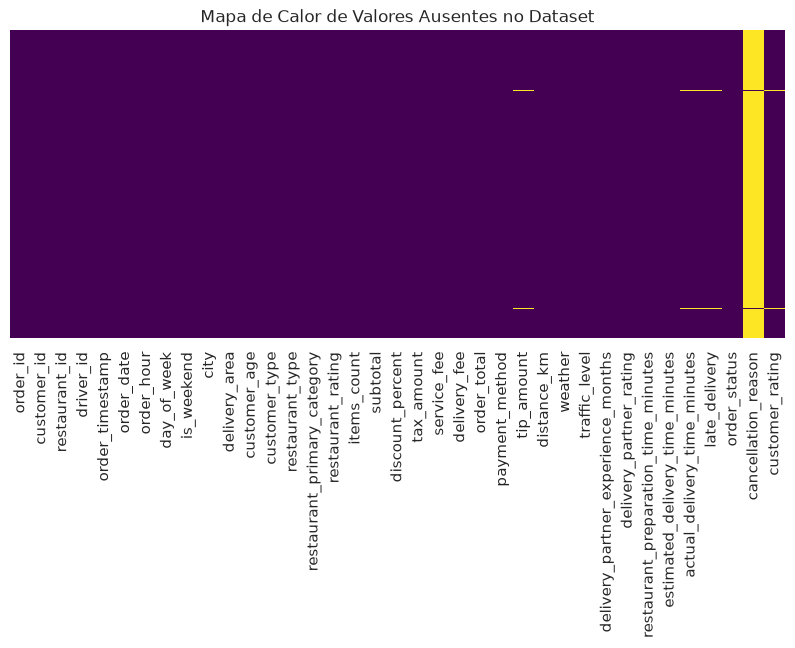

In [3]:
valores_ausentes = df.isnull().sum()
porcentagem_ausentes = (df.isnull().sum() / len(df)) * 100
tabela_ausentes = pd.DataFrame(
    {"Quantidade": valores_ausentes, "Porcentagem (%)": porcentagem_ausentes}
)

print("--- Tabela de Valores Ausentes ---")
display(tabela_ausentes[tabela_ausentes["Quantidade"] > 0])

# Gráfico de Mapa de Calor de Valores Ausentes
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de Calor de Valores Ausentes no Dataset")
plt.show()

# 4. Detecção de Outliers (Método IQR)
Utilizamos o cálculo do **Intervalo Interquartil (IQR = Q3 - Q1)** para definir os limites matemáticos dos dados discrepantes na variável `actual_delivery_time_minutes`. Em seguida, exibimos o gráfico de **Boxplot**.

### Explicação dos Outliers:
* Os limites calculados revelam entregas atípicas com tempos de espera excessivos.
* **Origem Provável:** Condições extremas de trânsito (`High`), episódios de chuva/tempestade (`weather`) ou atrasos severos no tempo de preparo do restaurante.

--- Análise Estatística de IQR para 'actual_delivery_time_minutes' ---
Q1: 25.0 | Q3: 42.0 | IQR: 17.0
Limites: Inferior = -0.5 | Superior = 67.5
Quantidade de Outliers: 1657 (3.31%)


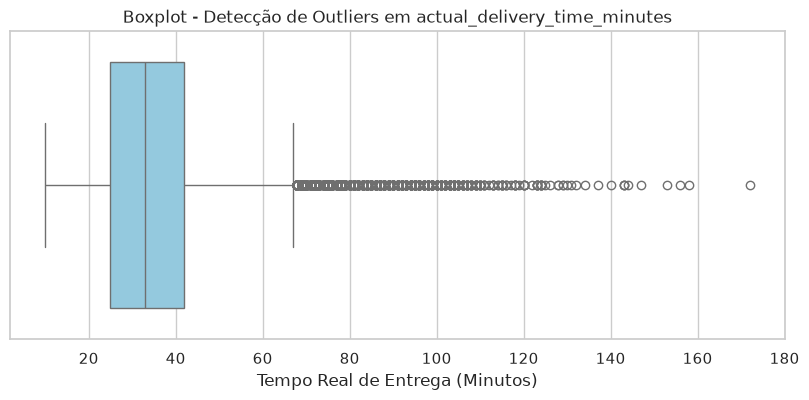

In [4]:
col_outlier = "actual_delivery_time_minutes"
q1 = df[col_outlier].quantile(0.25)
q3 = df[col_outlier].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df[
    (df[col_outlier] < limite_inferior) | (df[col_outlier] > limite_superior)
]

print(f"--- Análise Estatística de IQR para '{col_outlier}' ---")
print(f"Q1: {q1} | Q3: {q3} | IQR: {iqr}")
print(
    f"Limites: Inferior = {limite_inferior} | Superior = {limite_superior}"
)
print(
    f"Quantidade de Outliers: {len(outliers)} ({(len(outliers)/len(df))*100:.2f}%)"
)

# Visualização com Boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[col_outlier], color="skyblue")
plt.title(f"Boxplot - Detecção de Outliers em {col_outlier}")
plt.xlabel("Tempo Real de Entrega (Minutos)")
plt.show()

# 5. Análise de Correlação e Multicolinearidade
Calculamos a matriz de correlação de Pearson para as variáveis numéricas e apresentamos um Mapa de Calor (Heatmap) para visualizar como as variáveis se relacionam entre si.

### Discussão sobre Multicolinearidade:
* Variáveis financeiras como `subtotal`, `tax_amount`, `service_fee` e `order_total` apresentam forte correlação positiva (|r| > 0.7).
* **Atenção:** Em etapas de modelagem preditiva, manter todas essas variáveis num mesmo modelo pode gerar problemas de multicolinearidade. É recomendável utilizar apenas o valor total do pedido (`order_total`) ou apenas o `subtotal`.

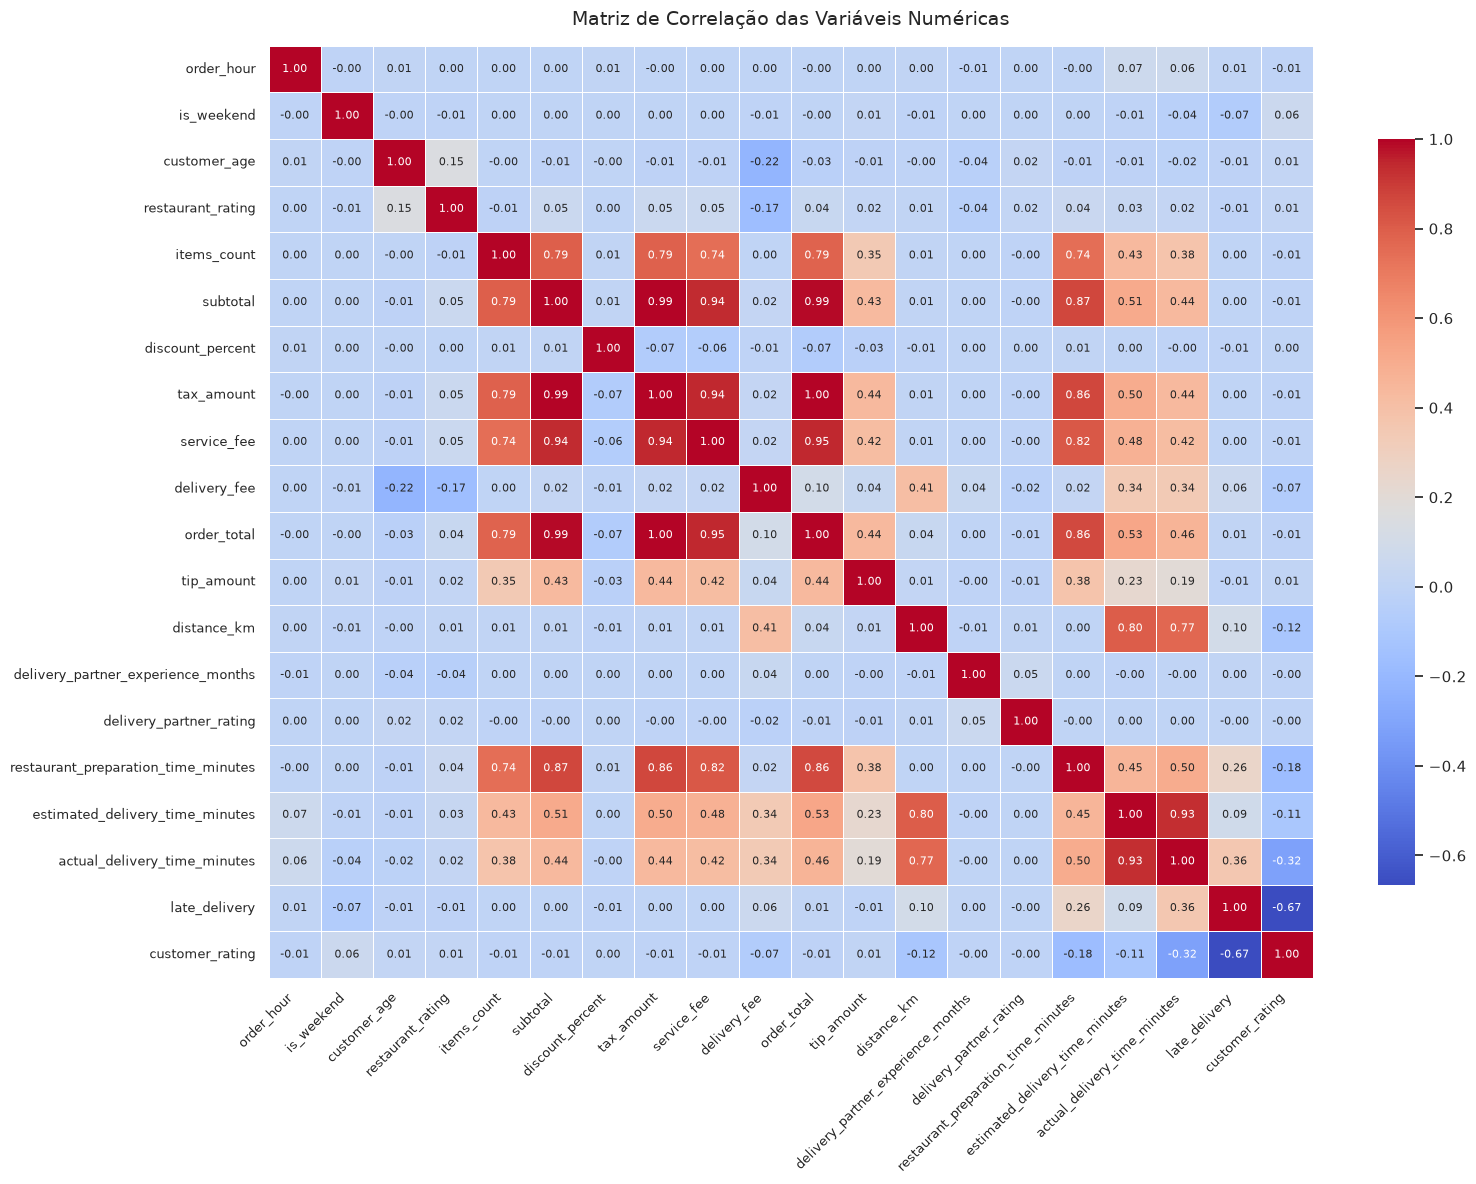

--- Pares de Variáveis com Alta Correlação (|r| > 0.7) ---
Par: subtotal <-> items_count | Correlação: 0.79
Par: tax_amount <-> items_count | Correlação: 0.79
Par: tax_amount <-> subtotal | Correlação: 0.99
Par: service_fee <-> items_count | Correlação: 0.74
Par: service_fee <-> subtotal | Correlação: 0.94
Par: service_fee <-> tax_amount | Correlação: 0.94
Par: order_total <-> items_count | Correlação: 0.79
Par: order_total <-> subtotal | Correlação: 0.99
Par: order_total <-> tax_amount | Correlação: 1.00
Par: order_total <-> service_fee | Correlação: 0.95
Par: restaurant_preparation_time_minutes <-> items_count | Correlação: 0.74
Par: restaurant_preparation_time_minutes <-> subtotal | Correlação: 0.87
Par: restaurant_preparation_time_minutes <-> tax_amount | Correlação: 0.86
Par: restaurant_preparation_time_minutes <-> service_fee | Correlação: 0.82
Par: restaurant_preparation_time_minutes <-> order_total | Correlação: 0.86
Par: estimated_delivery_time_minutes <-> distance_km | Correl

In [9]:
import os

os.makedirs("../reports/figures", exist_ok=True)

# Seleção de variáveis numéricas
df_numeric = df.select_dtypes(include=[np.number])
matriz_corr = df_numeric.corr()

# Configuração da figura com espaço suficiente
plt.figure(figsize=(16, 12))

# Mapa de calor com fonte ajustada e formatação limpa
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",  # Mantém 2 casas decimais
    annot_kws={"size": 8},  # Fonte pequena para não encavalar os números
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title("Matriz de Correlação das Variáveis Numéricas", fontsize=14, pad=15)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()

plt.savefig("../reports/figures/correlation_matrix.png", dpi=300)
plt.show()

# Identificação dos pares com alta correlação
print("--- Pares de Variáveis com Alta Correlação (|r| > 0.7) ---")
for i in range(len(matriz_corr.columns)):
    for j in range(i):
        if abs(matriz_corr.iloc[i, j]) > 0.7:
            col1 = matriz_corr.columns[i]
            col2 = matriz_corr.columns[j]
            val = matriz_corr.iloc[i, j]
            print(f"Par: {col1} <-> {col2} | Correlação: {val:.2f}")

# 6. Painel de Visualização de Dados
Para finalizar a análise exploratória, construímos um painel com 4 gráficos combinando diferentes aspectos do dataset:
1. **Histograma:** Distribuição contínua dos valores dos pedidos.
2. **Scatter Plot:** Relação entre distância de entrega (km) e o tempo real decorrido.
3. **Gráfico de Barras:** Frequência de pedidos por categoria de restaurante.
4. **Boxplot Categórico:** Variação do tempo de entrega de acordo com as condições do clima.

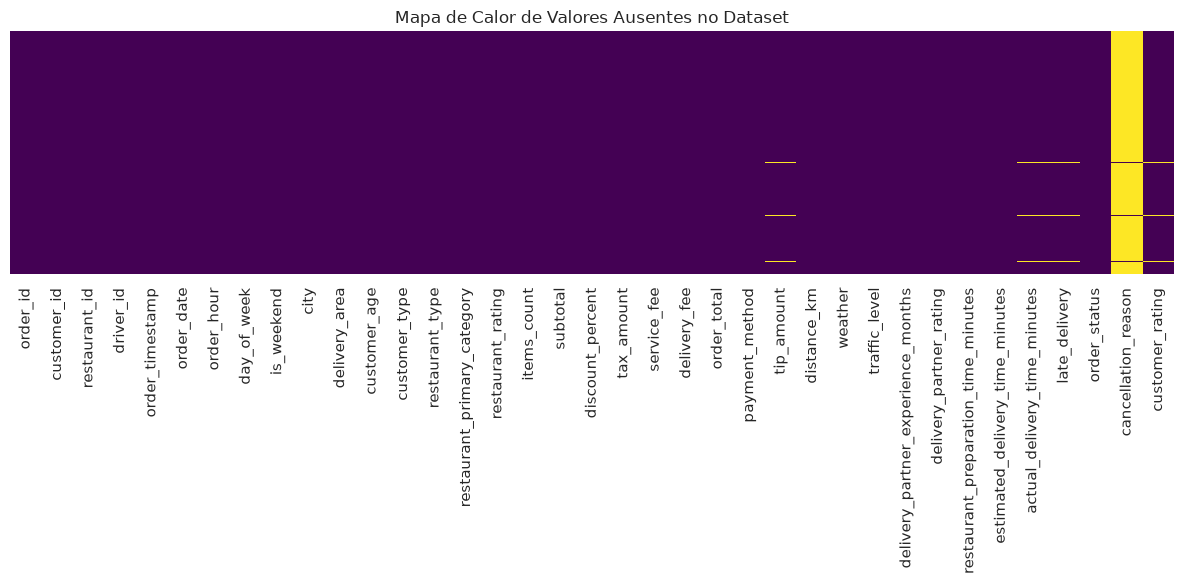

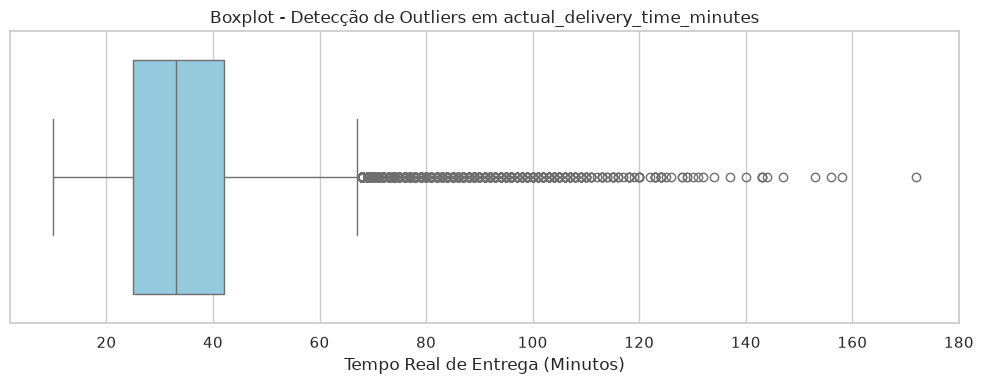

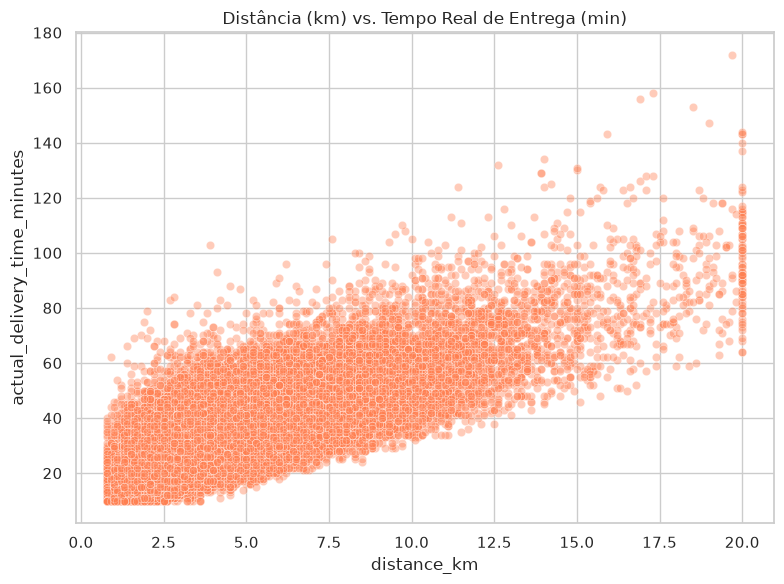

/tmp/ipykernel_23347/108104472.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


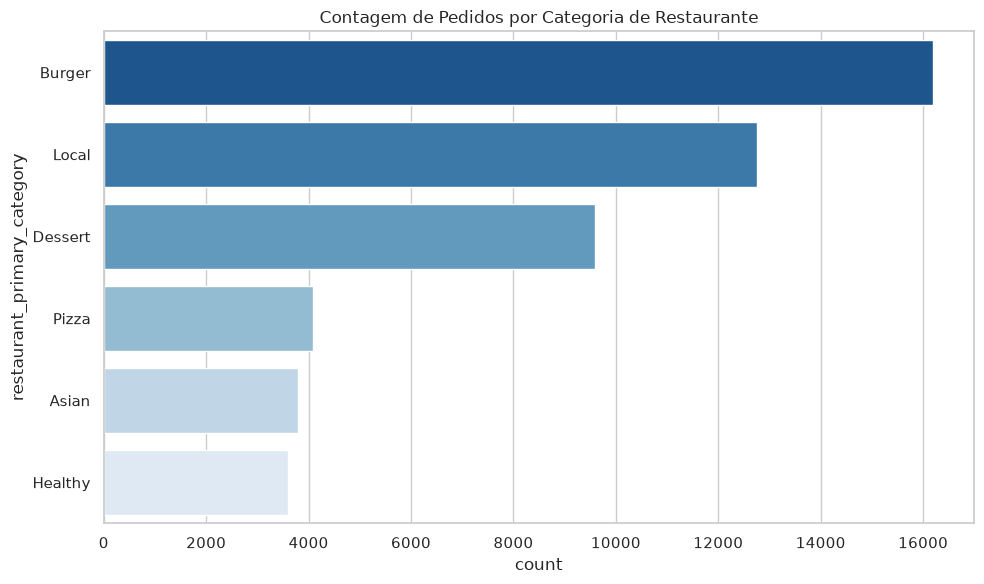

In [10]:
import os

os.makedirs("../reports/figures", exist_ok=True)

# 1. Mapa de Calor de Valores Ausentes
plt.figure(figsize=(12, 6))

# Aspecto 'auto' para ocupar todo o espaço do container gráfico
sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis",
    yticklabels=False,
)

plt.title("Mapa de Calor de Valores Ausentes no Dataset")
plt.tight_layout()
plt.savefig("../reports/figures/missing_values.png", dpi=300)
plt.show()

# 2. Boxplot de Outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["actual_delivery_time_minutes"], color="skyblue")
plt.title("Boxplot - Detecção de Outliers em actual_delivery_time_minutes")
plt.xlabel("Tempo Real de Entrega (Minutos)")
plt.tight_layout()
plt.savefig("../reports/figures/outliers_boxplot.png", dpi=300)
plt.show()

# 3. Scatter Plot (Distância vs Tempo)
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="distance_km",
    y="actual_delivery_time_minutes",
    alpha=0.4,
    color="coral",
)
plt.title("Distância (km) vs. Tempo Real de Entrega (min)")
plt.tight_layout()
plt.savefig("../reports/figures/regression_scatter.png", dpi=300)
plt.show()

# 4. Contagem por Categoria de Restaurante
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y="restaurant_primary_category",
    order=df["restaurant_primary_category"].value_counts().index,
    palette="Blues_r",
)
plt.title("Contagem de Pedidos por Categoria de Restaurante")
plt.tight_layout()
plt.savefig("../reports/figures/restaurant_categories.png", dpi=300)
plt.show()